# Project Overview

This notebook simulates spiking neural networks using the Izhikevich neuron model, The main goal is to investigate how the proportion of neurons receiving direct stimulus affects the stability and accuracy of stimulus decoding. The workflow includes generating various input stimuli, running network simulations, and applying Bayesian decoding to population spiking activity to assess how well different stimuli can be distinguished based on the network's output.

In [2]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import norm
from matplotlib.gridspec import GridSpec
from sklearn.metrics import roc_curve, auc
import warnings
warnings.filterwarnings("ignore")

## Izhikevich Network

Define neuron types and network parameters for the Izhikevich model.

In [3]:
p_RS  = [0.02, 0.2, -65, 8] # regular spiking settings for excitatory neurons (RS)
p_IB  = [0.02, 0.2, -55, 4] # intrinsically bursting (IB)
p_CH  = [0.02, 0.2, -50, 2] # chattering (CH)
p_FS  = [0.1, 0.2, -65, 8] # fast spiking (FS)
p_TC  = [0.02, 0.25, -65, 0.05] # thalamic-cortical (TC) (doesn't work well)
p_LTS = [0.02, 0.25, -65, 8] # low-threshold spiking (LTS)
p_RZ  = [0.1, 0.26, -65, 2] # resonator (RZ)

In [4]:
default_izhikevich_params = {
    "Ne": 800,
    "Ni": 200,
    "T": 1000,
    "p_e" : p_RS,
    "p_i": p_LTS,
    "w_Ne": 0.60,
    "w_Ni": -1.6,
    "conn_prob": 1.0
}

In [5]:
class IzhikevichNetwork:
    
    def __init__(self, Ne, Ni, T, p_e, p_i, w_Ne, w_Ni,conn_prob):
        self.Ne = Ne
        self.Ni = Ni
        self.size = Ne + Ni
        self.T = T
        self.threshold = 30

        # Parameters for excitatory & inhibitory neurons
        a_e, b_e, c_e, d_e = p_e
        a_i, b_i, c_i, d_i = p_i

        self.resting_potential = d_e

        re = np.random.rand(Ne, 1)
        ri = np.random.rand(Ni, 1)

        self.a = np.vstack((a_e * np.ones((Ne, 1)), a_i + 0.08 * ri))
        self.b = np.vstack((b_e * np.ones((Ne, 1)), b_i - 0.05 * ri))
        self.c = np.vstack((c_e + 15 * re**2, c_i * np.ones((Ni, 1))))
        self.d = np.vstack((d_e - 6 * re**2, d_i * np.ones((Ni, 1))))


        mask_e = (np.random.rand(self.size, Ne) < conn_prob).astype(float)
        mask_i = (np.random.rand(self.size, Ni) < conn_prob).astype(float)

        self.S = np.hstack((
            w_Ne * np.random.rand(self.size, Ne) * mask_e,
            w_Ni * np.random.rand(self.size, Ni) * mask_i
        ))

    def run_simulation(self, I_current=None):

        firings = np.array([]).reshape(0, 2)
        current_history = np.zeros((self.size, self.T))
        voltage_history = np.zeros((self.size, self.T))
        recovery_history = np.zeros((self.size, self.T))

        v = np.random.normal(self.resting_potential, 20, size=(self.size, 1))
        u = self.b * v

        for t in range(self.T):

            # 1. input current for this time step for each neuron
            I = np.vstack((10 * np.random.randn(self.Ne, 1), 10 * np.random.randn(self.Ni, 1))) # random current "noise"
            if t > 1:  # Add synaptic contributions from previously fired neurons
                I += np.sum(self.S[:, fired], axis=1).reshape(-1, 1)
            if I_current is not None:
                I += I_current[:, t].reshape(-1, 1)

            # 2. Update the membrane potential (v) and recovery variable (u)
            v += 0.5 * (0.04 * v**2 + 5 * v + 140 - u + I)
            v += 0.5 * (0.04 * v**2 + 5 * v + 140 - u + I)
            u += self.a * (self.b * v - u)

            # 3. Store the current voltage in the history matrix
            v = np.clip(v, -100, self.threshold)
            current_history[:, t] = I.flatten()
            voltage_history[:, t] = v.flatten()
            recovery_history[:, t] = u.flatten()

            # 4. Check for neurons that fired 
            fired = np.where(v >= self.threshold)[0]

            # 5. Reset the membrane potential and recovery variable for fired neurons
            if fired.size > 0:
                v[fired] = self.c[fired]  # Reset v
                u[fired] = u[fired] + self.d[fired]  # Adjust u

                # 6. Record the spikes (time and neuron indices)
                firings = np.vstack((firings, np.hstack((t * np.ones((fired.size, 1)), fired.reshape(-1, 1)))))

        return firings, current_history, voltage_history, recovery_history

## Stimulus Generation

In [6]:
default_stimulus_params = {
    "Ne": default_izhikevich_params["Ne"],
    "Ni": default_izhikevich_params["Ni"],
    "perc_input_neurons": 0.05,
    "T": default_izhikevich_params["T"],
    "start": 100,
    "end": 900,
    "max_input":10,
    "frequency":10,
    "phase": 0 
}

In [7]:
def generate_inputs(Ne, Ni, perc_input_neurons, T, start, end, max_input, frequency, phase, stimulus=None):

    num_neurons = Ne + Ni

    time = np.arange(T) / 1000.0 #per second

    input_neurons = np.random.choice(Ne, size=int(max(1, perc_input_neurons * Ne)), replace=False)

    I = np.zeros((num_neurons, T))

    if stimulus is None:
        return I, [None]

    for t in range(T):
        if start <= t < end:
            if stimulus == "ramp":
                I[input_neurons, t] = max_input * (t - start) / (end - start)
            elif stimulus == "step":
                I[input_neurons, t] = max_input
            elif stimulus == "sinus":
                sinus_val = max_input * np.sin(2 * np.pi * frequency * time[t] + phase)
                I[input_neurons, t] = np.clip(sinus_val, 0, None)
            elif stimulus == "cosine":
                cos_val = max_input * np.cos(2 * np.pi * frequency * time[t] + phase)
                I[input_neurons, t] = np.clip(cos_val, 0, None)
            elif stimulus == "sinus_amplitude":
                offset_val = (5 + max_input) * np.sin(2 * np.pi * frequency * time[t] + phase)
                I[input_neurons, t] = np.clip(offset_val, 0, None)
            elif stimulus == "sinus_offset":
                offset_val = max_input * np.sin(2 * np.pi * frequency * time[t] + phase)
                I[input_neurons, t+5] = np.clip(offset_val, 0, None)

    return I, input_neurons

## Visualization Functions

In [8]:
def plot_raster(T, firings, Ne, Ni):
    plt.figure(figsize=(9, 7))
    plt.scatter(firings[:, 0], firings[:, 1], s=1, c='k')
    # plot a horizontal line to separate excitatory and inhibitory neurons:
    plt.axhline(y=Ne, color='k', linestyle='-', linewidth=1)
    # indicate excitatory and inhibitory neurons with text annotations with background color white:
    plt.text(0.8, 0.76, 'excitatory', color='k', fontsize=12, ha='left', va='center', transform=plt.gca().transAxes, bbox=dict(facecolor='white', alpha=1)) 
    plt.text(0.8, 0.84, 'inhibitory', color='k', fontsize=12, ha='left', va='center', transform=plt.gca().transAxes, bbox=dict(facecolor='white', alpha=1))

    plt.xlabel('Time (ms)')
    plt.ylabel('Neuron index')
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['bottom'].set_visible(False)
    plt.gca().spines['left'].set_visible(False)
    plt.xlim([0, T])
    plt.ylim([0, Ne+Ni])
    plt.yticks(np.arange(0, Ne+Ni+1, 200))
    plt.tight_layout()
    plt.show()

In [9]:
def plot_population_firing_rate(firings, num_neurons=1000, bin_size=20, T=1000):
    bins = np.arange(0, T + bin_size, bin_size)
    spike_counts, _ = np.histogram(firings[:,0], bins)
    firing_rate_timeseries = spike_counts / (bin_size / 1000.0 * num_neurons)
    plt.figure(figsize=(6, 3))
    plt.title('Firing rate')
    plt.plot(bins[:-1], firing_rate_timeseries, label='Firing Rate')
    plt.xlabel('Time [ms]')
    plt.ylabel('f [Hz]')
    plt.xlim(0, T)
    plt.show()

In [10]:
def plot_variable(T, data, neuron_index, var_type="voltage"):
    var_labels = {
        "voltage": ("Voltage Evolution", "Membrane Potential (mV)"),
        "current": ("Input Current Evolution", "Input Current (A)"),
        "recovery": ("Recovery Variable Evolution", "Recovery Variable (u)")
    }
    
    title, ylabel = var_labels.get(var_type, ("Unknown Variable", "Value"))
    
    trace = data[neuron_index, :]
    
    plt.figure()
    plt.xlim(0, T)
    plt.plot(trace, label=f"Neuron {neuron_index}")
    plt.title(f"{title} of Neuron {neuron_index}")
    plt.xlabel("Time (ms)")
    plt.ylabel(ylabel)
    plt.legend()
    plt.show()

In [11]:
def plot_full_summary(T, firings, Ne, Ni, neuron_index, current_history, voltage_history, recovery_history, input_current=None):

    fig = plt.figure(figsize=(16, 12))
    gs = GridSpec(3, 2, height_ratios=[2, 1, 1])

    # --- LEFT COLUMN ---

    # Raster plot (top left)
    ax_raster = fig.add_subplot(gs[0, 0])
    ax_raster.scatter(firings[:, 0], firings[:, 1], s=1, c='k')
    ax_raster.axhline(y=Ne, color='k', linestyle='-', linewidth=1)
    ax_raster.set_xlabel('Time (ms)')
    ax_raster.set_ylabel('Neuron index')
    ax_raster.set_title('Raster Plot')
    ax_raster.set_xlim([0, T])
    ax_raster.set_ylim([0, Ne+Ni])

    # Mean population firing rate (middle left)
    ax_rate = fig.add_subplot(gs[1, 0])
    bin_size = 20
    bins = np.arange(0, T + bin_size, bin_size)
    spike_counts, _ = np.histogram(firings[:, 0], bins)
    firing_rate_timeseries = spike_counts / (bin_size / 1000.0 * (Ne + Ni))
    ax_rate.plot(bins[:-1], firing_rate_timeseries)
    ax_rate.set_title('Population Firing Rate')
    ax_rate.set_xlabel('Time (ms)')
    ax_rate.set_ylabel('Hz')

    # Voltage of selected neuron (bottom left)
    ax_voltage = fig.add_subplot(gs[2, 0])
    ax_voltage.plot(voltage_history[neuron_index, :])
    ax_voltage.set_title(f'Voltage (Neuron {neuron_index})')
    ax_voltage.set_xlabel('Time (ms)')
    ax_voltage.set_ylabel('Membrane Potential (mV)')

    # --- RIGHT COLUMN ---

    # Total input current (top right)
    ax_total = fig.add_subplot(gs[0, 1])
    ax_total.plot(current_history[neuron_index, :], color='tab:orange')
    ax_total.set_title(f'Total Input Current (Neuron {neuron_index})')
    ax_total.set_xlabel('Time (ms)')
    ax_total.set_ylabel('Current')

    # Recovery variable (middle right)
    ax_recovery = fig.add_subplot(gs[1, 1])
    ax_recovery.plot(recovery_history[neuron_index, :])
    ax_recovery.set_title(f'Recovery (Neuron {neuron_index})')
    ax_recovery.set_xlabel('Time (ms)')
    ax_recovery.set_ylabel('u')

    # Stimulus input (bottom right)
    ax_input = fig.add_subplot(gs[2, 1])
    if input_current is not None:
        ax_input.plot(input_current[neuron_index, :])

    ax_input.set_ylim(0, 30)
    ax_input.set_title(f'Stimulus Input (Neuron {neuron_index})')
    ax_input.set_xlabel('Time (ms)')
    ax_input.set_ylabel('Input')

    plt.tight_layout()
    #plt.savefig(f"summary_{name}.png")
    plt.show()

# Visualization

### Sinus-like stimuli

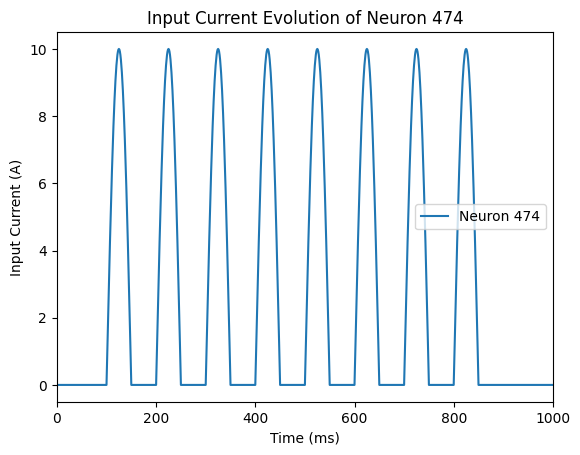

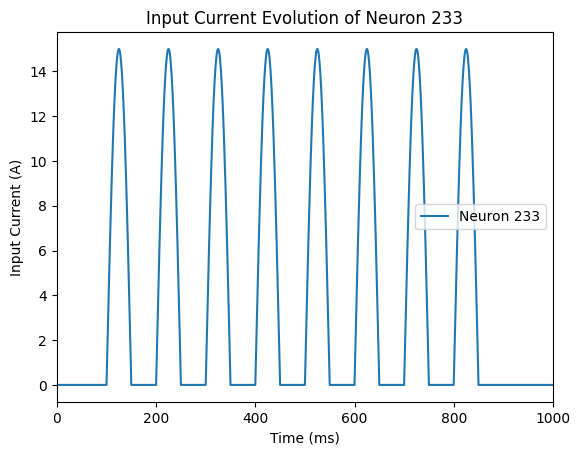

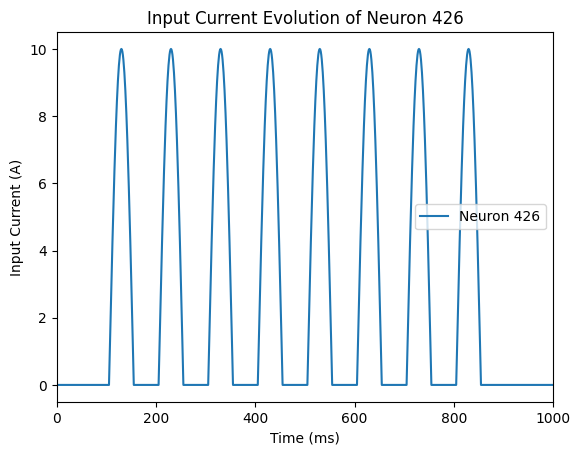

In [12]:
for stimulus in ["sinus", "sinus_amplitude", "sinus_offset"]:
    inputs, input_neurons= generate_inputs(**default_stimulus_params, stimulus=stimulus)
    plot_variable(default_stimulus_params["T"], inputs, input_neurons[0], var_type="current")

### Raster plots for different connectivities

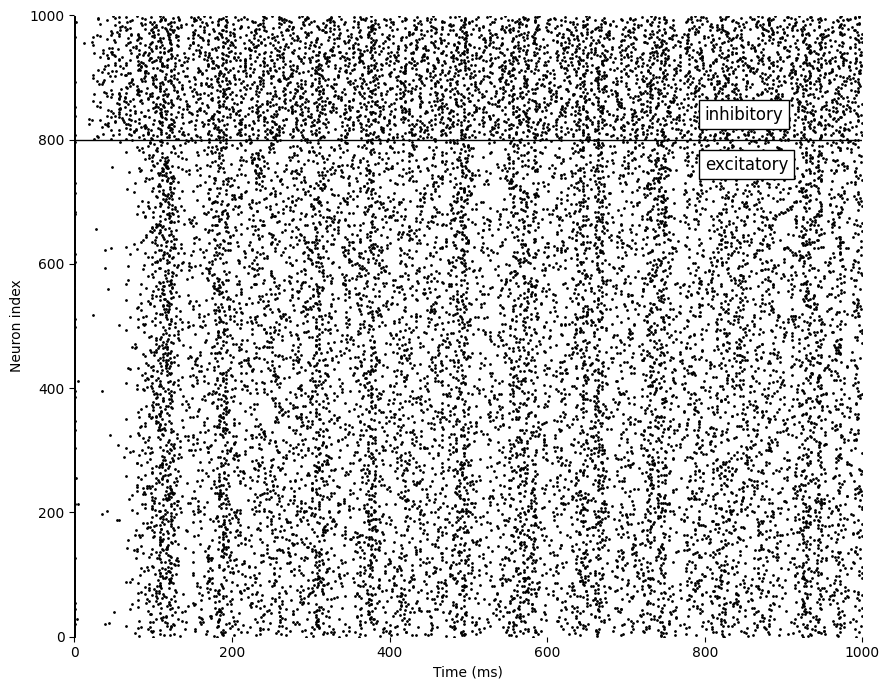

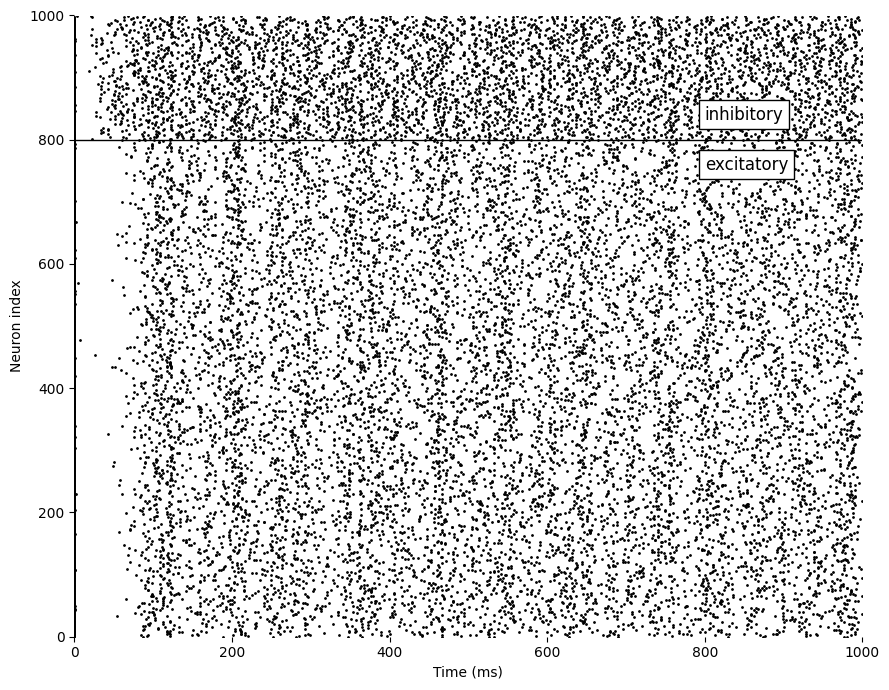

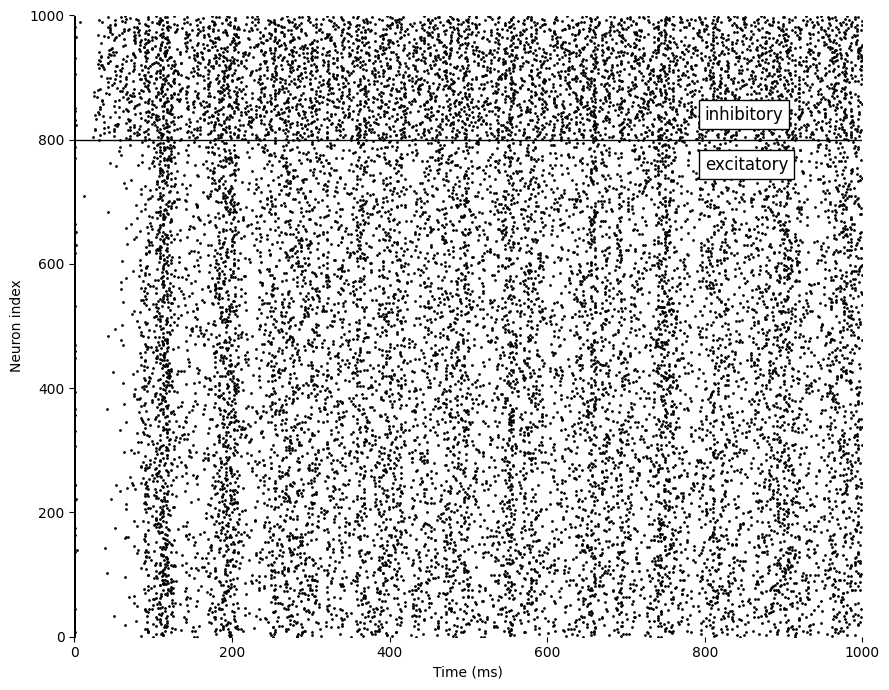

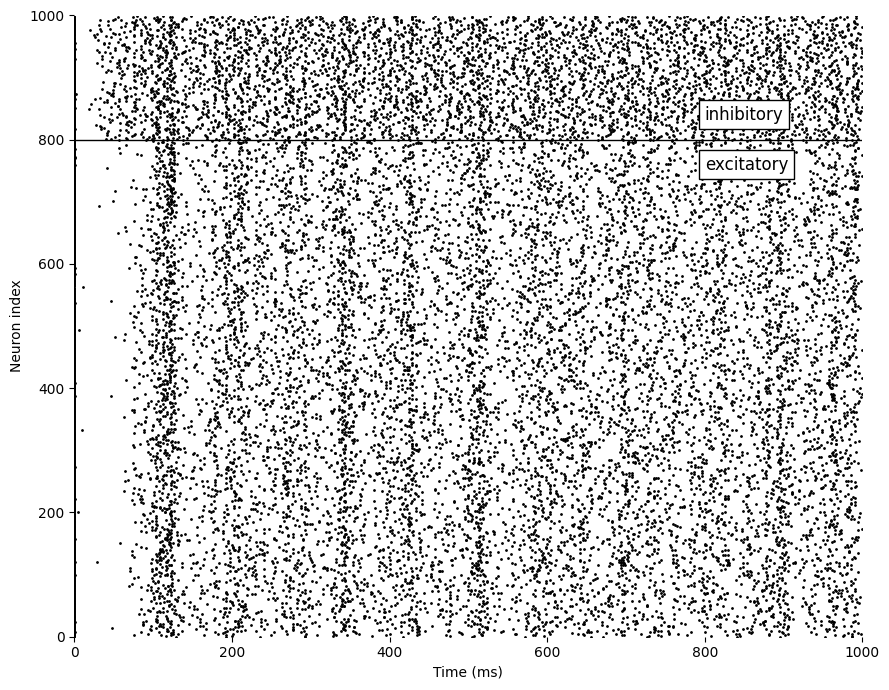

In [13]:
conn_probs = [1, 0.1, 0.01, 0.001]

for conn_prob in conn_probs:
    izhikevich_params = default_izhikevich_params.copy()
    izhikevich_params.update({"conn_prob": conn_prob})
    net = IzhikevichNetwork(**default_izhikevich_params)
    firings, _, _, _ = net.run_simulation()
    plot_raster(izhikevich_params["T"], firings, izhikevich_params["Ne"], izhikevich_params["Ni"])


### Network Summary for different stimuli

########################################    Stimulus: sinus     ########################################


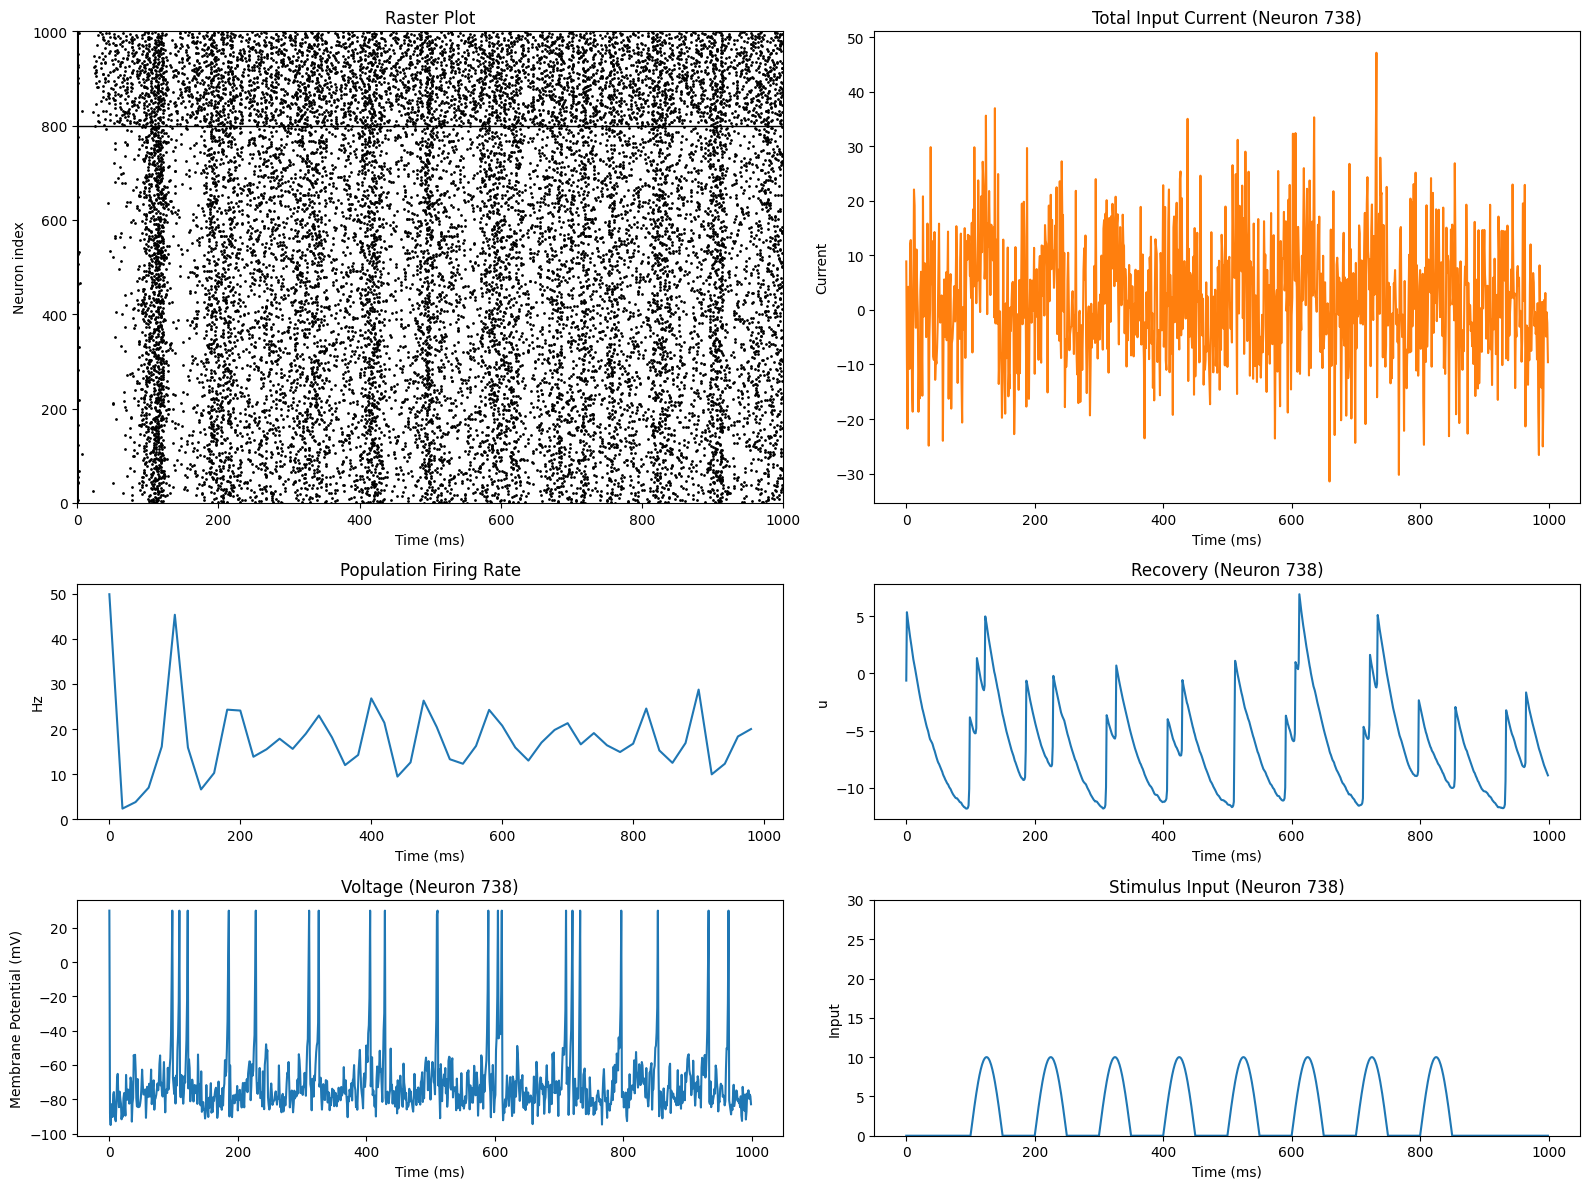

########################################    Stimulus: sinus_amplitude     ########################################


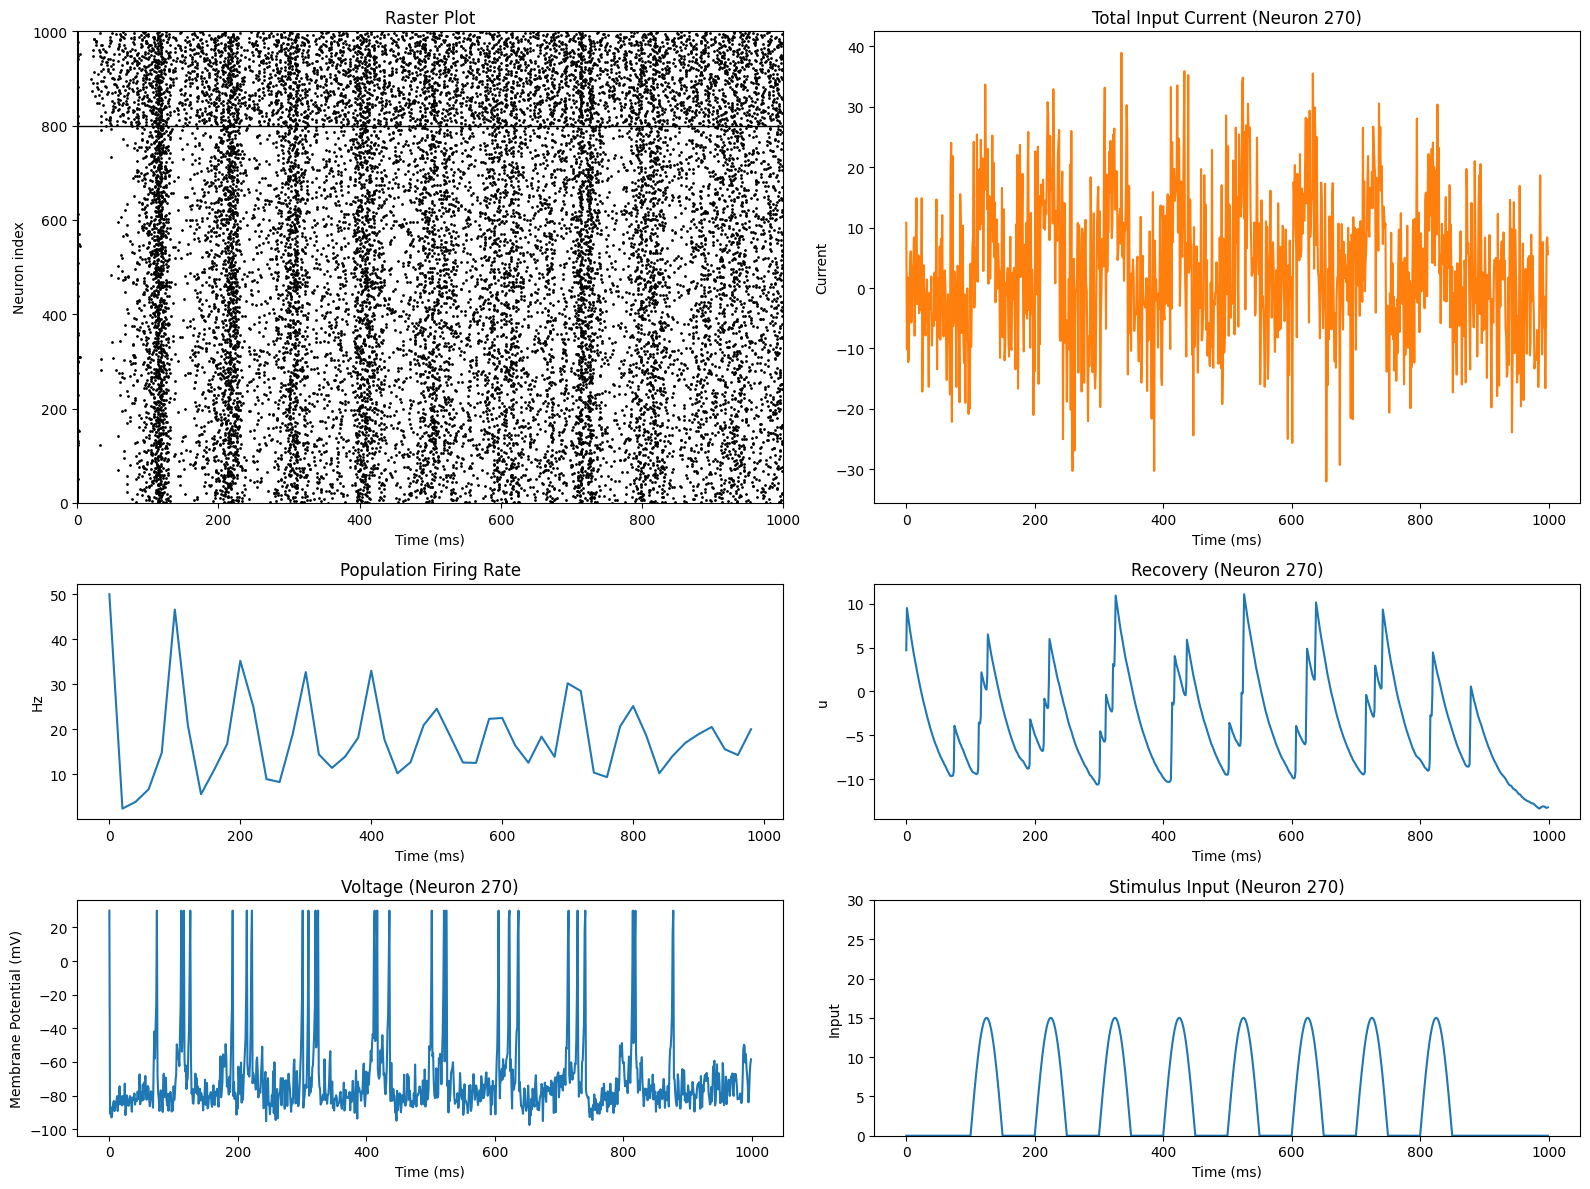

########################################    Stimulus: sinus_offset     ########################################


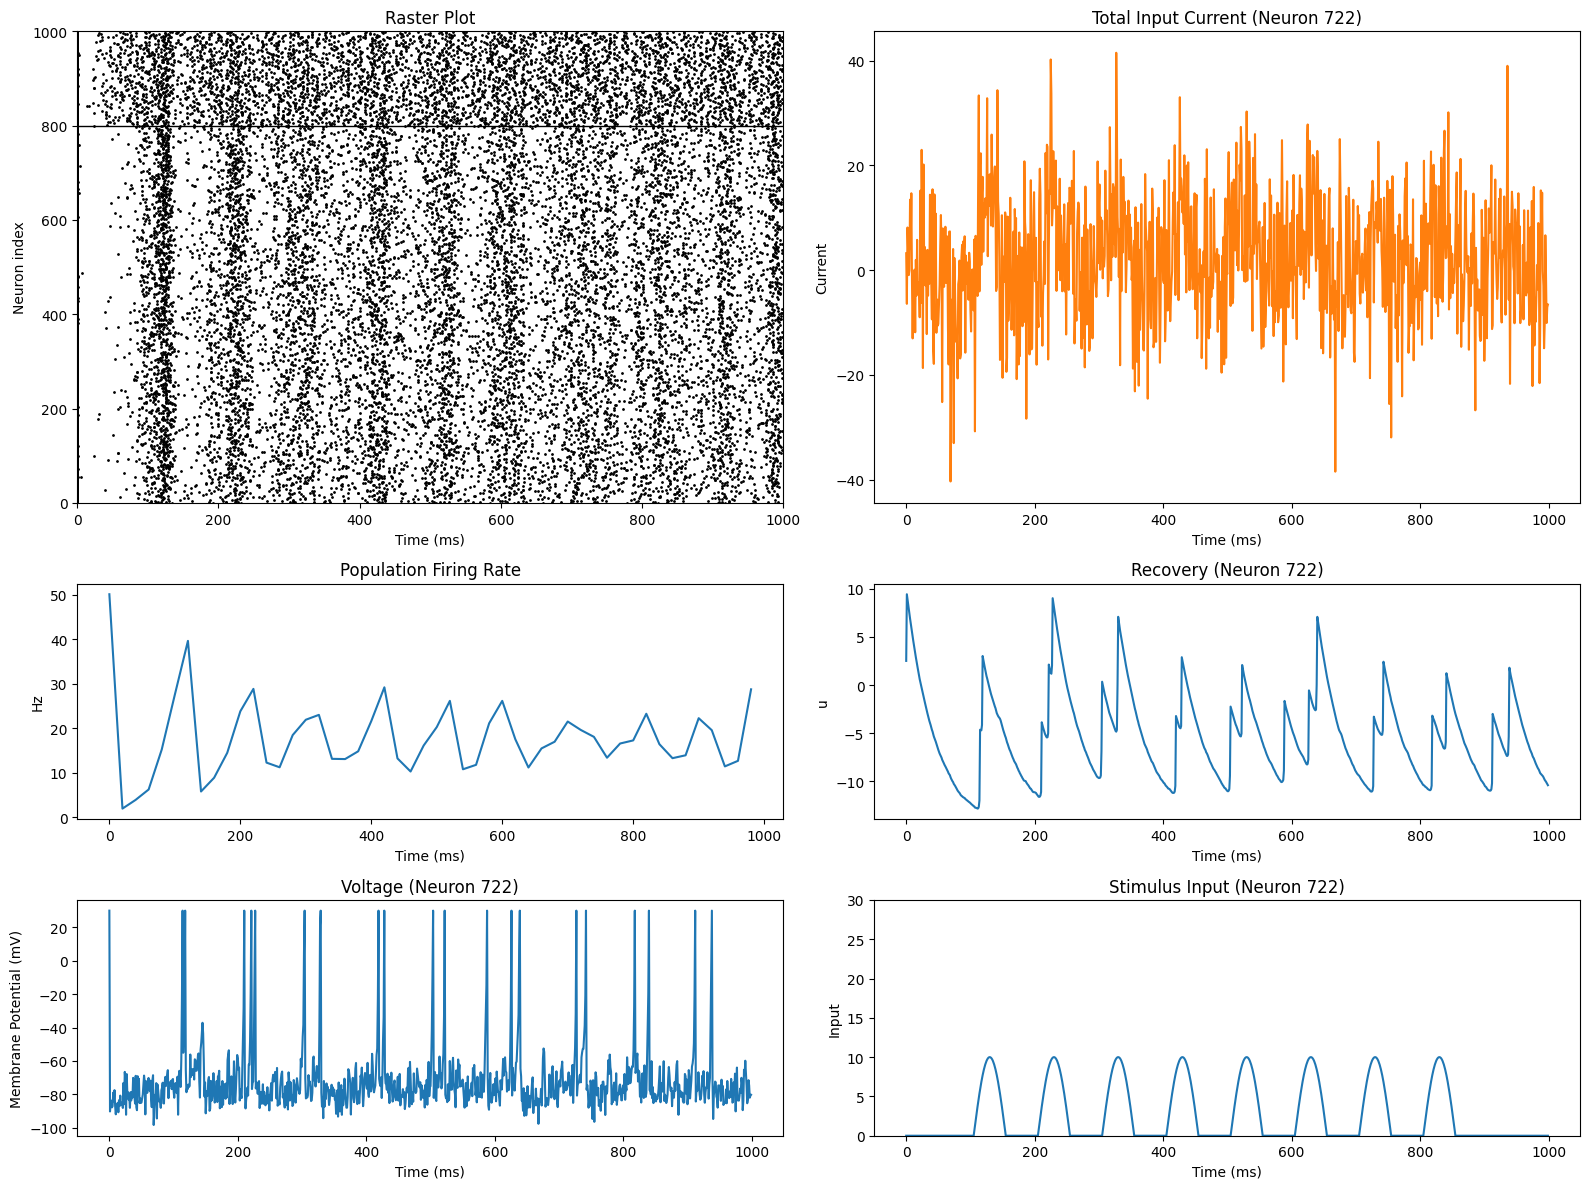

########################################    Stimulus: step     ########################################


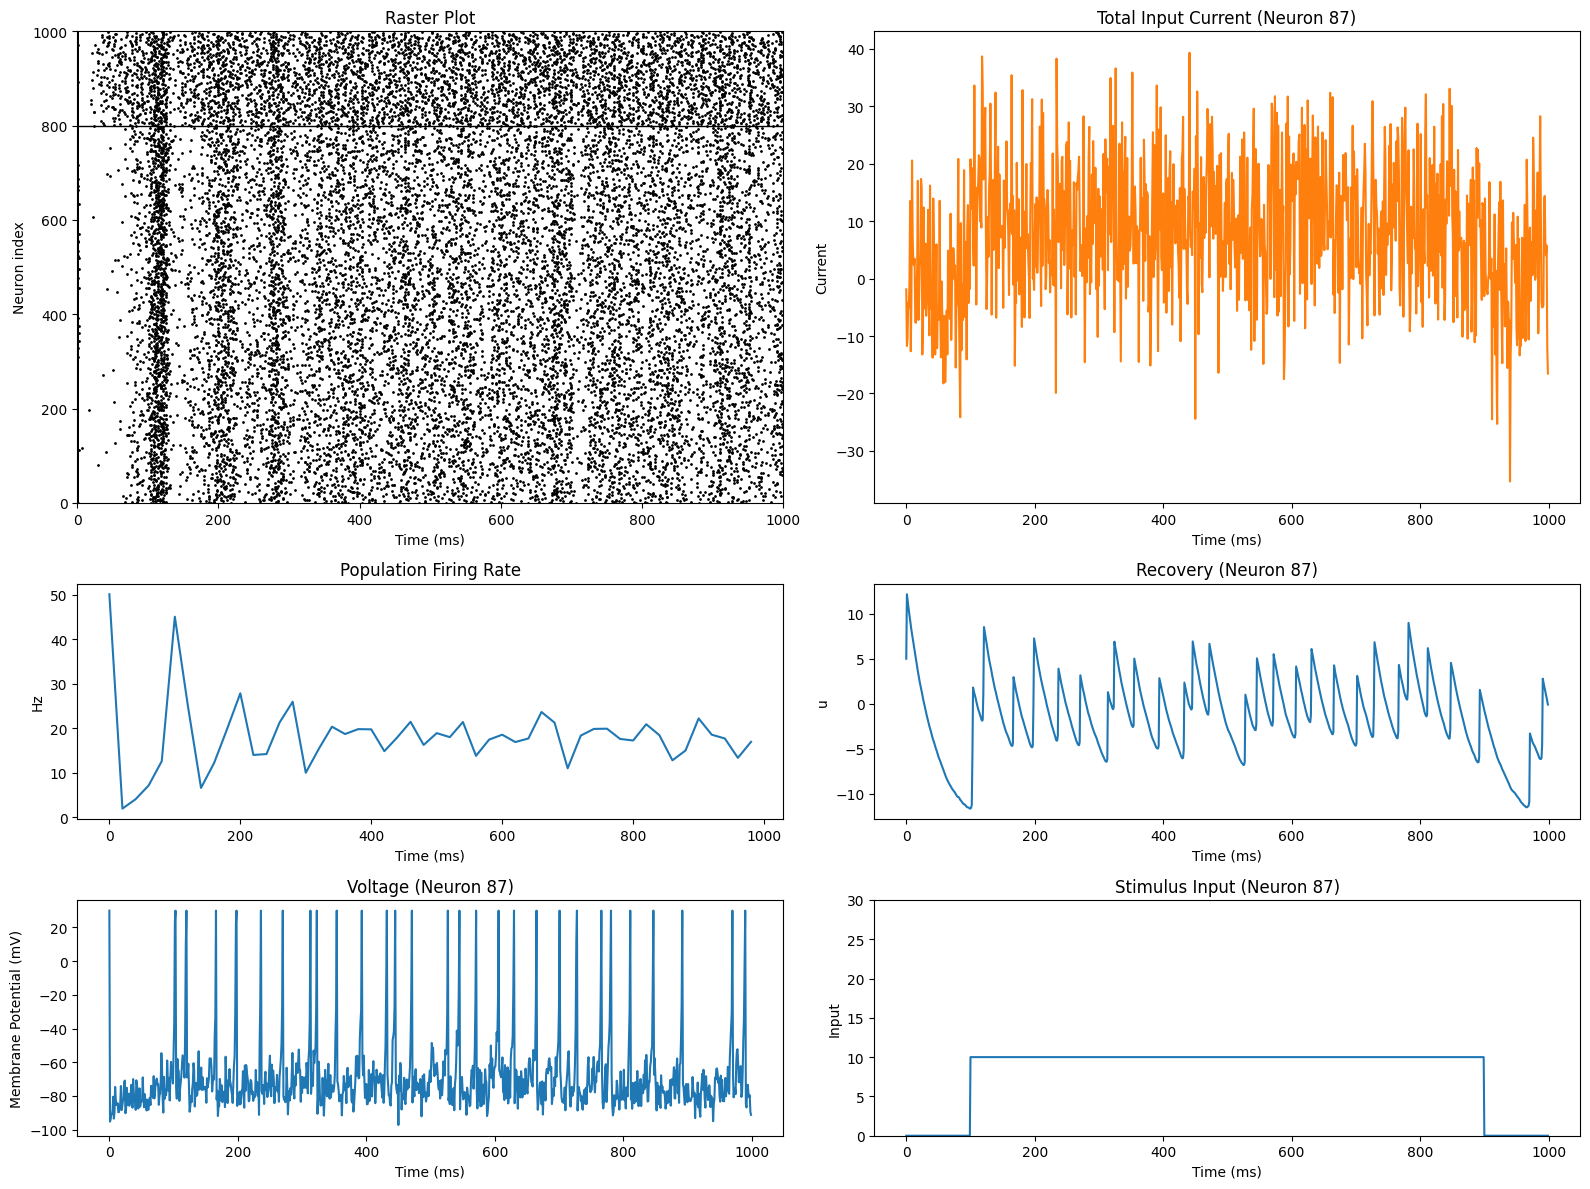

########################################    Stimulus: ramp     ########################################


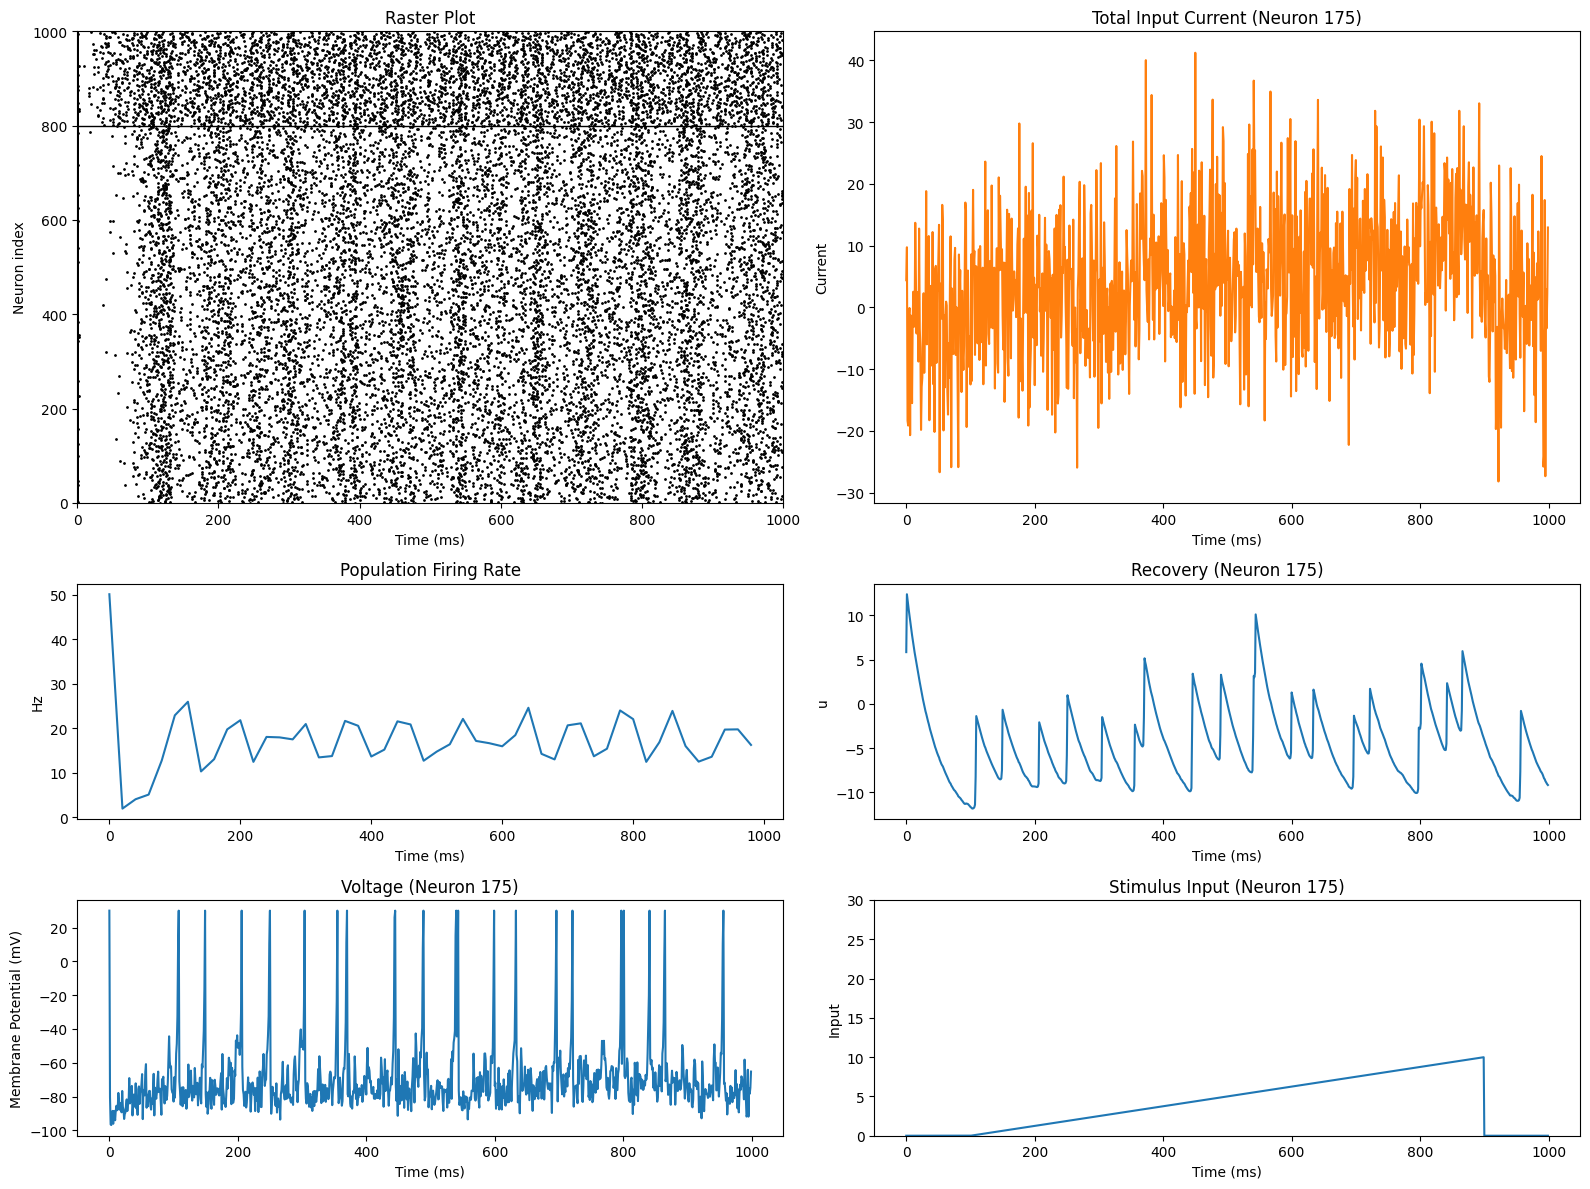

########################################    Stimulus: cosine     ########################################


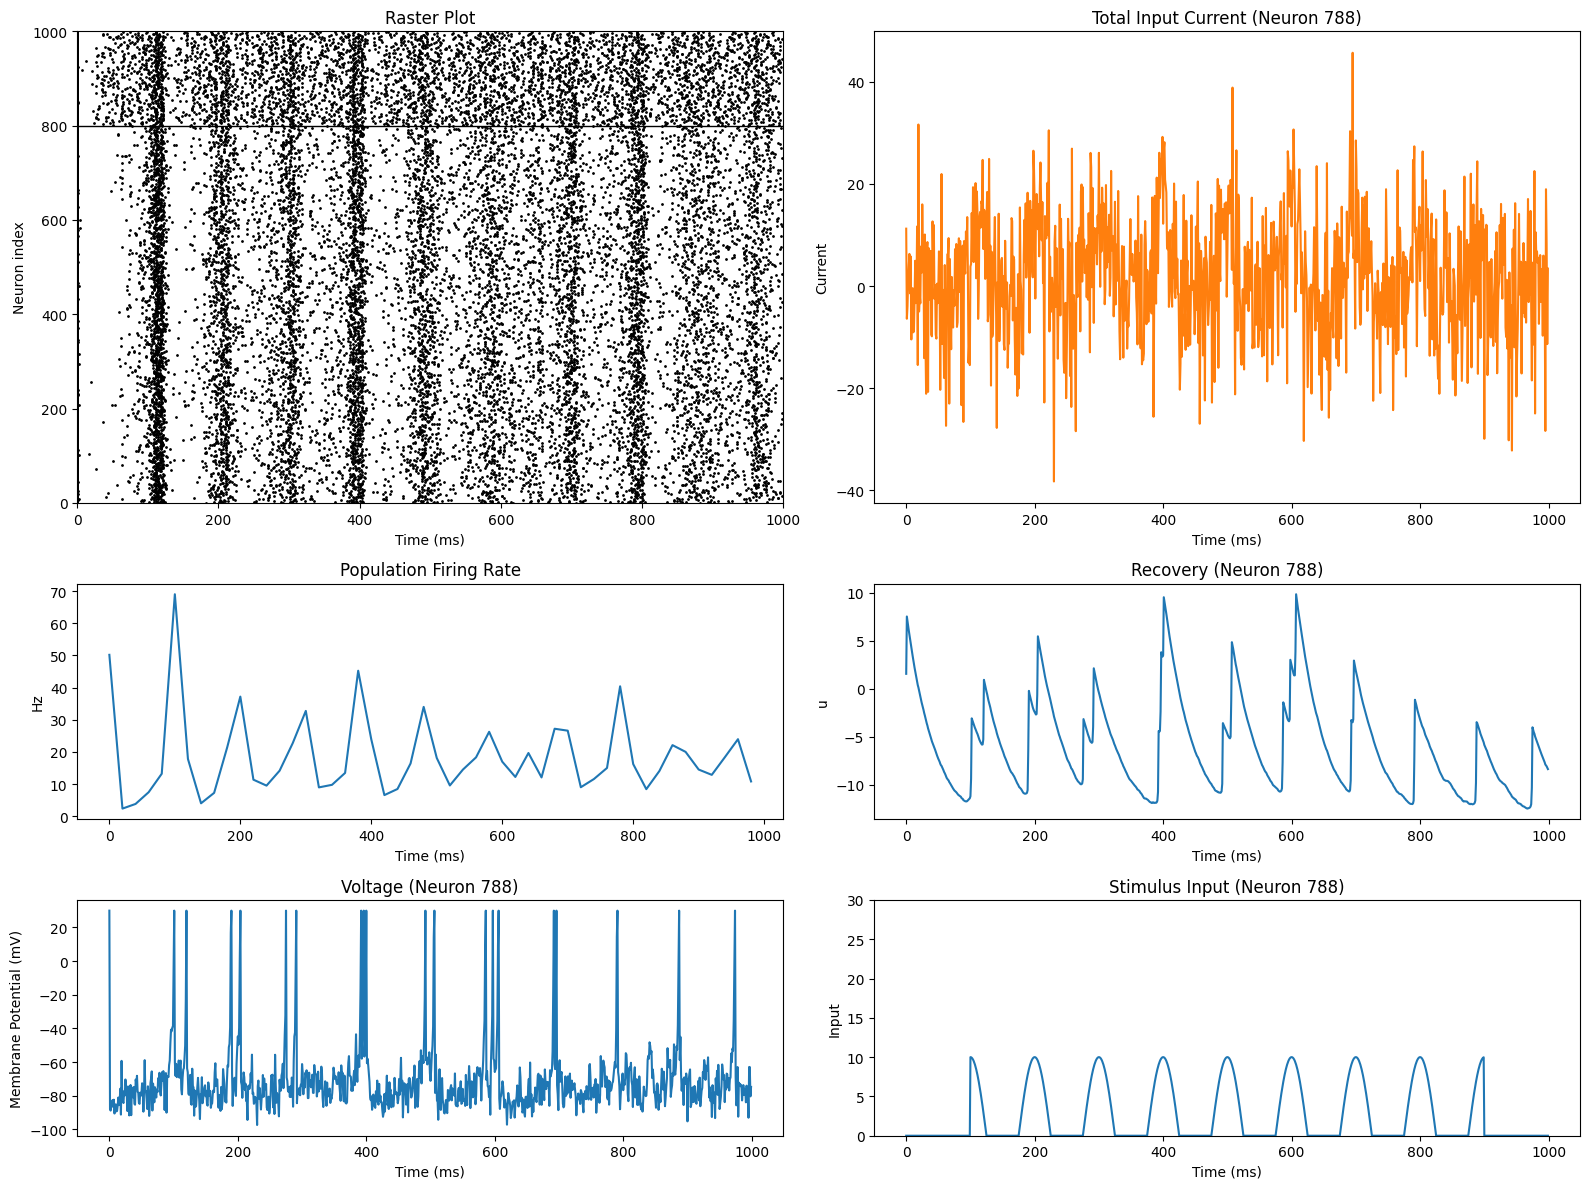

In [14]:
input_currents = ["sinus", "sinus_amplitude", "sinus_offset", "step", "ramp", "cosine"]

for input_current in input_currents:
    print("#"*40 + f"    Stimulus: {input_current}     "+ "#"*40)
    input_current, input_neurons = generate_inputs(**default_stimulus_params, stimulus=input_current)
    net = IzhikevichNetwork(**default_izhikevich_params)
    firings, current_history, voltage_history, recovery_history = net.run_simulation(input_current)
    plot_full_summary(
        net.T, firings, net.Ne, net.Ni, input_neurons[0],
        current_history, voltage_history, recovery_history,
        input_current=input_current
    )


# Decoding

In [ ]:
def get_simulation_data(izhikevich_params, stimulus_params, stimuli_types = ["sinus", "sinus_offset"], num_trials = 10):
    
    data = {}

    train_fraction = 0.7
    train_trials = int(num_trials * train_fraction)

    for stimulus_type in stimuli_types:
        rates = []

        for trial in range(num_trials):

            np.random.seed(trial)
            input, input_neurons = generate_inputs(**stimulus_params, stimulus=stimulus_type)
            net = IzhikevichNetwork(**izhikevich_params)
            firings, _, _, _ = net.run_simulation(input)
            
            bin_size = 10
            bins = np.arange(0, izhikevich_params["T"] + bin_size, bin_size)
            spike_counts, _ = np.histogram(firings[:, 0], bins)
            population_firing_rate = spike_counts / (bin_size / 1000.0 * net.size)
            
            rates.append(population_firing_rate)

        rates = np.array(rates)

        train_rates = rates[:train_trials]
        test_rates = rates[train_trials:]
        
        input, input_neurons = generate_inputs(**stimulus_params, stimulus=stimulus_type)

        data[stimulus_type] = {
            "train_rates": train_rates,
            "test_rates": test_rates,
            "stimulus": input[input_neurons[0]]
        }

    return data

In [ ]:
def estimate_likelihoods(stimuli_data):

    likelihoods = {}
    for stimulus_type, data in stimuli_data.items():
        rates = data["train_rates"]
        mean_rate = np.mean(rates, axis=0)
        std_rate = np.std(rates, axis=0)
        likelihoods[stimulus_type] = {"mean": mean_rate, "std": std_rate}
    return likelihoods

In [ ]:
def decode_stimulus(test_rate, likelihoods, priors=None):
    if priors is None:
        priors = {stimulus: 1 / len(likelihoods) for stimulus in likelihoods}  # Uniform prior

    log_posteriors = {}
    for stimulus, params in likelihoods.items():
        mean_rate = params["mean"]
        std_rate = params["std"]
        
        # Avoid division by zero in norm.pdf by adding a small epsilon to std_rate
        std_rate = np.clip(std_rate, a_min=1e-6, a_max=None)
        
        # Compute log-likelihood
        log_likelihood = np.sum(np.log(norm.pdf(test_rate, loc=mean_rate, scale=std_rate)))
        log_posteriors[stimulus] = log_likelihood + np.log(priors[stimulus])  # Add log-prior

    # Convert log-posteriors to posteriors
    max_log_posterior = max(log_posteriors.values())  # For numerical stability
    posteriors = {stimulus: np.exp(log_posteriors[stimulus] - max_log_posterior) for stimulus in log_posteriors}
    total = sum(posteriors.values())
    for stimulus in posteriors:
        posteriors[stimulus] /= total

    # Decode the stimulus with the highest posterior probability
    decoded_stimulus = max(posteriors, key=posteriors.get)
    return decoded_stimulus, posteriors

In [ ]:
def evaluate_decoding_accuracy(stimuli_data, likelihoods, show_missclassifications=False):
    correct = 0
    total = 0
    misclassified_counts = {}

    for stimulus_type, data in stimuli_data.items():
        rates = data["test_rates"]
        num_test_trials = rates.shape[0]
        for trial in range(num_test_trials):
            test_rate = rates[trial]
            decoded_stimulus, posterior = decode_stimulus(test_rate, likelihoods)
            if decoded_stimulus == stimulus_type:
                correct += 1
            else:
                key = (stimulus_type, decoded_stimulus)
                misclassified_counts[key] = misclassified_counts.get(key, 0) + 1
            total += 1

    accuracy = correct / total if total > 0 else 0

    if show_missclassifications and misclassified_counts:
        print("\nMisclassification summary (true → predicted: count):")
        for (true, pred), count in misclassified_counts.items():
            print(f"{true} → {pred}: {count}")

    return accuracy

In [ ]:
def get_binary_roc_data(stimuli_data, likelihoods, positive_stimulus_type):
    true_binary_labels = []
    positive_class_scores = []

    for stimulus_type, data in stimuli_data.items():
        rates = data["test_rates"]
        num_test_trials = rates.shape[0]
        for trial in range(num_test_trials):
            test_rate = rates[trial]
            _, posteriors = decode_stimulus(test_rate, likelihoods)
            
            true_binary_labels.append(1 if stimulus_type == positive_stimulus_type else 0)
            
            positive_class_scores.append(posteriors.get(positive_stimulus_type, 0))
            
    return np.array(true_binary_labels), np.array(positive_class_scores)

### Experimental Loop

In [ ]:
def run_experiment(
    izhikevich_params,
    stimulus_params,
    stimuli_types,
    num_trials=40,
    compute_roc=False,
    positive_stimulus=None,
    plot_roc=False,
    show_missclassifications=False
):

    stimuli_data = get_simulation_data(
        izhikevich_params,
        stimulus_params,
        stimuli_types=stimuli_types,
        num_trials=num_trials
    )

    likelihoods = estimate_likelihoods(stimuli_data)

    results = {}

    if compute_roc:
        if len(stimuli_types) != 2:
            raise ValueError("ROC analysis requires exactly two stimuli_types.")
        if positive_stimulus is None:
            raise ValueError("Must specify positive_stimulus for ROC analysis.")
        true_labels, scores = get_binary_roc_data(stimuli_data, likelihoods, positive_stimulus)
        fpr, tpr, thresholds = roc_curve(true_labels, scores)
        roc_auc = auc(fpr, tpr)
        results = {"auc": roc_auc, "fpr": fpr, "tpr": tpr, "thresholds": thresholds}
        if plot_roc:
            plt.figure()
            plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
            plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
            plt.xlim([0.0, 1.0])
            plt.ylim([0.0, 1.05])
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.title(f'ROC for {positive_stimulus} vs Others')
            plt.legend(loc="lower right")
            plt.show()

    accuracy = evaluate_decoding_accuracy(stimuli_data, likelihoods, show_missclassifications= show_missclassifications)
    results["accuracy"] = accuracy

    return results

# Analysis

### Comparison of decoding accuracy for different stimuli

In [ ]:
results_acc = run_experiment(
    izhikevich_params=default_izhikevich_params,
    stimulus_params=default_stimulus_params,
    stimuli_types= [ None , "sinus", "ramp", "sinus_amplitude", "sinus_offset", "step", "cosine"],
    num_trials=40,
    show_missclassifications=True
)
print(f"Accuracy: {results_acc["accuracy"]}")


Misclassification summary (true → predicted: count):
None → ramp: 5
None → cosine: 1
sinus → sinus_amplitude: 3
sinus → sinus_offset: 3
ramp → step: 2
sinus_amplitude → sinus: 4
sinus_amplitude → sinus_offset: 1
sinus_offset → sinus_amplitude: 2
sinus_offset → sinus: 2
sinus_offset → step: 1
step → ramp: 3
Accuracy: 0.6785714285714286


### ROC-Curve for distinguishing different sinus variantions

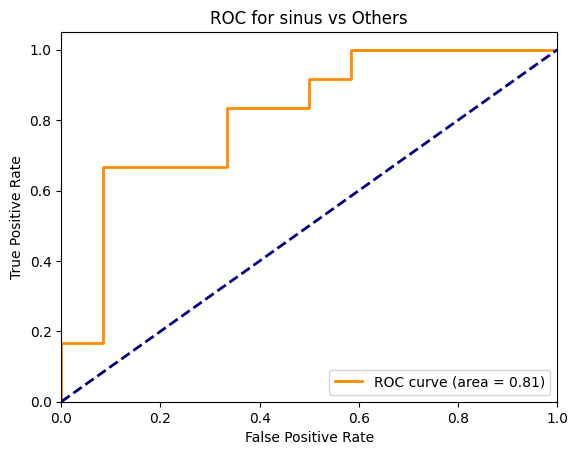


Misclassification summary (true → predicted: count):
sinus → sinus_offset: 3
sinus_offset → sinus: 4


In [ ]:
results_auc = run_experiment(
    izhikevich_params=default_izhikevich_params,
    stimulus_params=default_stimulus_params,
    stimuli_types=["sinus", "sinus_offset"],
    num_trials=40,
    compute_roc=True,
    positive_stimulus="sinus",
    plot_roc=True,
    show_missclassifications=True
)

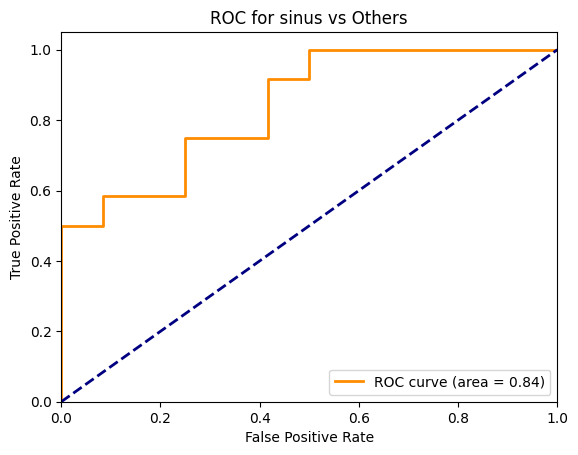


Misclassification summary (true → predicted: count):
sinus → sinus_amplitude: 3
sinus_amplitude → sinus: 5


In [ ]:
results_auc = run_experiment(
    izhikevich_params=default_izhikevich_params,
    stimulus_params=default_stimulus_params,
    stimuli_types=["sinus", "sinus_amplitude"],
    num_trials=40,
    compute_roc=True,
    positive_stimulus="sinus",
    plot_roc=True,
    show_missclassifications=True
)

## Impact of Network Parameters on distinugishing temporal differences in a sinus-curve-like input

### Network weights

In [ ]:
weigths = {
    "se_si" : (0.6, -1.6), # strong excitatory, strong inhibitory
    "se_wi" : (0.6, -0.6), # strong excitatory, weak inhibitory
    "we_si" : (0.3, -1.6), # weak excitatory, strong inhibitory
    "we_wi" : (0.3, -0.6)  # weak excitatory, weak inhibitory
}

for n, w in weigths.items():
    izhikevich_params = default_izhikevich_params.copy()
    izhikevich_params.update({"w_Ne": w[0],"w_Ni": w[1],})

    results_auc = run_experiment(
        izhikevich_params=izhikevich_params,
        stimulus_params=default_stimulus_params,
        stimuli_types=["sinus", "sinus_offset"],
        num_trials=40,
        compute_roc=True,
        positive_stimulus="sinus",
        show_missclassifications=True
    )

    print(f"{n}\t{results_auc["auc"]:.3f}\t{results_auc["accuracy"]:.3f}")


Misclassification summary (true → predicted: count):
sinus → sinus_offset: 3
sinus_offset → sinus: 4
se_si	0.812	0.708

Misclassification summary (true → predicted: count):
sinus_offset → sinus: 10
se_wi	0.931	0.583

Misclassification summary (true → predicted: count):
sinus → sinus_offset: 2
we_si	1.000	0.917

Misclassification summary (true → predicted: count):
sinus_offset → sinus: 2
we_wi	0.951	0.917


### Connectivity and Percentage of Input Neurons

In [ ]:
perc_values = [0.01, 0.05, 0.1, 0.5]
conn_values = [0.01, 0.1, 0.95, 1.0]

heatmap_data = np.zeros((len(perc_values), len(conn_values)))

for i, perc in enumerate(perc_values):
    for j, c in enumerate(conn_values):

        current_stim_params = default_stimulus_params.copy()
        current_stim_params["perc_input_neurons"] = perc
        current_izh_params = default_izhikevich_params.copy()
        current_izh_params["conn_prob"] = c

        res = run_experiment(
            izhikevich_params=current_izh_params,
            stimulus_params=current_stim_params,
            stimuli_types=["sinus", "sinus_offset"],
            num_trials=40,
        )
        heatmap_data[i, j] = res["accuracy"]


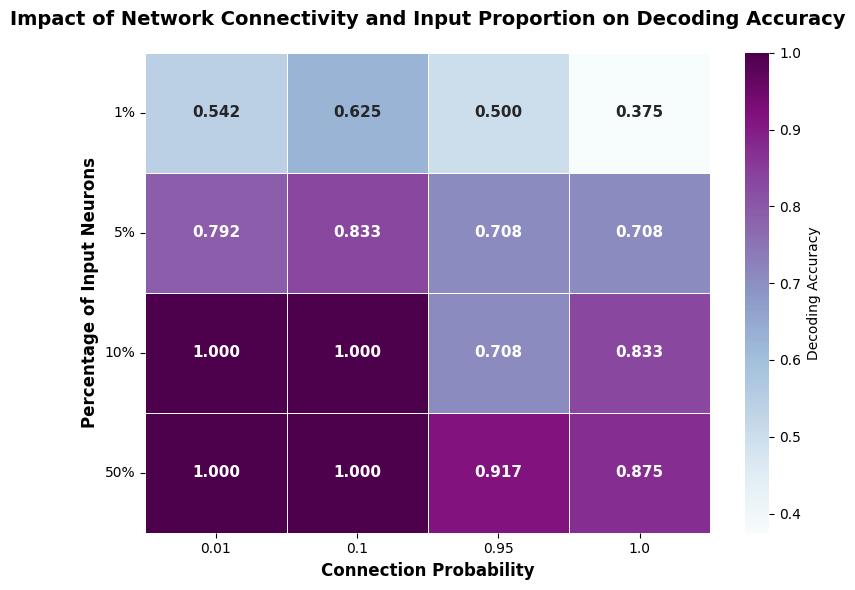

In [ ]:
plt.figure(figsize=(8, 6))
ax = sns.heatmap(
    heatmap_data, 
    annot=True, 
    fmt='.3f',
    xticklabels=conn_values, 
    yticklabels=perc_values, 
    cmap="BuPu",
    cbar_kws={'label': 'Decoding Accuracy'},
    annot_kws={'size': 11, 'weight': 'bold'},
    linewidths=0.5,
    linecolor='white'
)

plt.title("Impact of Network Connectivity and Input Proportion on Decoding Accuracy", 
          fontsize=14, fontweight='bold', pad=20)
plt.xlabel("Connection Probability", fontsize=12, fontweight='bold')
plt.ylabel("Percentage of Input Neurons", fontsize=12, fontweight='bold')

# Improve tick labels
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)

# Add percentage signs to y-axis labels
y_labels = [f"{int(val*100)}%" for val in perc_values]
ax.set_yticklabels(y_labels, rotation=0, fontsize=10)

plt.tight_layout()
plt.show()